In [12]:
from pprint import pprint
import os, sys
from pathlib import Path
from typing import Optional, Any, Callable, Union
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from copy import deepcopy
from collections import defaultdict
from time import perf_counter

# import wandb
# from dask.distributed import Client, as_completed
import networkx as nx
import torch
import numpy as np
import numpy.linalg as npla
import pandas as pd
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    precision_recall_curve, auc, roc_curve
    )
from sklearn.model_selection import KFold
from tqdm import tqdm
import optuna
import omegaconf as oc
from omegaconf import OmegaConf
import matplotlib.pyplot as plt

from t_regs.multilinear_ops.tensor_products import multi_mode_product as mmp
from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_regressor import TuckerRegressor
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.synthetic_data.generate_lr_data import (
    generate_sparse_low_tucker_rank_tensor,
    generate_low_rank_data,
    generate_smooth_low_tucker_rank_tensor
    )
from t_regs.synthetic_data.regression import (
    generate_tensor_regression_predictors,
    generate_tensor_regression_response
    )

path = Path().cwd().parent.parent.parent
sys.path.append(str(path))

from experiments.synthetic.hp_study_utils import get_model, get_data
from experiments.synthetic.synthetic_study_utils import (
    register_resolvers,
    init_rada_rgd
    )

register_resolvers()

In [13]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.tensor_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [4, 4, 4]
conf.data.ranks = [3,3,3]
conf.data.expanded = True
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)

{'regression_type': 'logistic', 'tensor_type': 'sparse_low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None], 'cardinalities': [4, 4, 4], 'expanded': True}


In [14]:
conf.model_cfg.regressor.feature_ranks[0] = 3
conf.model_cfg.regressor.feature_ranks[1] = 3
conf.model_cfg.regressor.feature_ranks[2] = 3
conf.model_cfg.verbosity = 2
conf.model_cfg.max_it= 100
conf.model_cfg.max_time= 100
conf.rada_rgd_cfg.Tk = 20
conf.rada_rgd_cfg.max_it = 10000
pprint(conf.model_cfg)

{'model_name': 'LR-Tucker', 'regressor': {'regression_type': 'logistic', 'feature_dims': '${data.dims}', 'feature_ranks': [3, 3, 3], 'feature_manifolds': ['${Steifel:${..feature_dims[0]}, ${..feature_ranks[0]}, ${...device}}', '${Steifel:${..feature_dims[1]}, ${..feature_ranks[1]}, ${...device}}', '${Steifel:${..feature_dims[2]}, ${..feature_ranks[2]}, ${...device}}']}, 'tau': 0.0, 'ldas': [0.0, 0.0, 0.0], 'lda_core': 0.0, 'thetas': [0.0, 0.0, 0.0], 'Ds': None, 'Ls': [None, None, None], 'subproblem_solvers': {'U_1': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[0]},${mul:${data.dims[0]},${..regressor.feature_ranks[0]}}}', 'U_2': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[1]},${mul:${data.dims[1]},${..regressor.feature_ranks[1]}}}', 'U_3': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[2]},${mul:${data.dims[2]},${..regressor.feature_ranks[2]}}}', 'C': '${init_rada_rgd:${rada_rgd_cfg},${..lda_core},${mul_list:${..regressor.feature_ranks}}}'}, 'dataloader_cfg': None, 'main_algorithm': 'BCD_RADA_RGD

In [15]:
# torch.manual_seed(1)
seed = 2
conf.data.seed= seed
data = get_data(conf.data)
conf.model_cfg.init_with_hosvd_of_grad = True
conf.model_cfg.max_it = 100
conf.model_cfg.regressor.seed = seed
conf.model_cfg.max_time = 12309101230
model = get_model(conf.model_cfg, 'cuda:3')
data['X'] = data['X'].to(model.device)
data['y'] = data['y'].to(model.device)
X_train, X_val = data['X'][300:], data['X'][:300]
y_train, y_val = data['y'][300:].reshape(-1, 1), data['y'][:300].reshape(-1, 1)
model.fit(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val,
    seed=seed
)

Initializing with the HoSVD of the gradient evaluated at 0
Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
  1          0.8800         0.7133       3.5025624130e-01    7.7256e-02       7.7256e-02       3.6125e-02       2.7758e-07       1.3568e-02     
  2          0.9467         0.7067       1.9181586650e-01    8.2475e-02       8.2475e-02       4.8212e-02       1.7934e-09       1.3395e-03     
  3          0.97

In [18]:
def search_l1_path(
    base_model: TuckerRegressorBCD,
    mode: int,
    lda_range: list[float],
    X, y, X_val, y_val,
    rada_cfg,
    verbosity = 1
    ):
    path_model = deepcopy(base_model)
    best_v_score = model._v_score
    best_t_score = model._t_score
    best_v_loss = model._v_loss
    best_t_loss = model._t_loss
    results = defaultdict(list)
    results['baseline'] = {
        't_score': model._t_score,
        'v_score': model._v_score,
        't_loss': model._t_loss,
        'v_loss': model._v_loss,
    }
    best_model = deepcopy(base_model)
    for i, lda in enumerate(lda_range):
        ts = perf_counter()
        # path_model = deepcopy(path_model)
        if verbosity:
            print(f"Running iteration {i+1}/{len(lda_range)} with lda={lda:.3e}")
        path_model.ldas[mode-1] = float(lda)
        dim = path_model.tucker_regressor.Us[mode-1].numel()
        problem, covariate_transform = path_model._initialize_U_subproblem(
            use_dloader=False,
            mode=mode,
            X=X,
            y=y,
            X_val=X_val,
            y_val=y_val,
            save_score_to_self=True,
        )
        rada_cfg.R = float(lda*dim**0.5)
        rada_cfg.beta1 = 0.1*30*3**0.5
        rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
        path_model.subproblem_solvers[f'U_{mode}'] = rada_rgd_solver
        rada_result = rada_rgd_solver.solve(
            problem,
            x0=path_model.tucker_regressor.Us[mode-1].detach().clone(),
            # y0=path_model.solver_results[f'U_{mode}'].point.y,
        )
        path_model.solver_results[f'U_{mode}'] = rada_result
        path_model.tucker_regressor.Us[mode-1].requires_grad = False
        path_model.tucker_regressor.Us[mode-1].copy_(
            rada_result.point.x.data
        )
        # path_model._BCD_fit(use_dloader=False, X=X, y=y, X_val=X_val, y_val=y_val, seed=0)
        # results['U_results'].append(rada_result.point.x.data.clone().detach())
        # results['U_sparsity'].append(
        #     float(rada_result.point.x.data.numel() - (rada_result.point.x.data != 0).sum()))
        # results['U_sparsity~'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.abs() > 1e-6).sum()))
        results['time'].append(perf_counter() - ts)
        results['v_score'].append(path_model._v_score)
        results['t_score'].append(path_model._t_score)
        results['v_loss'].append(path_model._v_loss)
        results['t_loss'].append(path_model._t_loss)
        # results['grad_norm'].append(float(rada_result.gradient_norm))
        results['lda'].append(float(lda))
        # results['model'].append(path_model)

        # if path_model._v_loss <= best_v_loss:
        if path_model._v_score >= best_v_score:
            best_model = deepcopy(path_model)
            best_v_score = best_model._v_score
            # best_t_score = best_model._t_score
            # best_v_loss = best_model._v_loss
            # best_t_loss = best_model._t_loss
    results['best_model'] = best_model
    return results


In [19]:
model.max_it = 200
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 100000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.8
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-3
rada_rgd_cfg.log_verbosity = 0
lda_range = np.logspace(np.log10(0.1*3/30**0.5),np.log10(3*2.5), 20)#[8:]
results = search_l1_path(
    model, 1, lda_range,
    X_train, y_train, X_val, y_val,
    rada_rgd_cfg,
    verbosity = 1
)

Running iteration 1/20 with lda=5.477e-02
Running iteration 2/20 with lda=7.096e-02
Running iteration 3/20 with lda=9.193e-02
Running iteration 4/20 with lda=1.191e-01
Running iteration 5/20 with lda=1.543e-01
Running iteration 6/20 with lda=1.999e-01
Running iteration 7/20 with lda=2.590e-01
Running iteration 8/20 with lda=3.355e-01
Running iteration 9/20 with lda=4.347e-01
Running iteration 10/20 with lda=5.631e-01
Running iteration 11/20 with lda=7.295e-01
Running iteration 12/20 with lda=9.451e-01
Running iteration 13/20 with lda=1.224e+00
Running iteration 14/20 with lda=1.586e+00
Running iteration 15/20 with lda=2.055e+00
Running iteration 16/20 with lda=2.662e+00
Running iteration 17/20 with lda=3.449e+00
Running iteration 18/20 with lda=4.469e+00
Running iteration 19/20 with lda=5.789e+00
Running iteration 20/20 with lda=7.500e+00


/tmp/ipykernel_1593283/2304561268.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


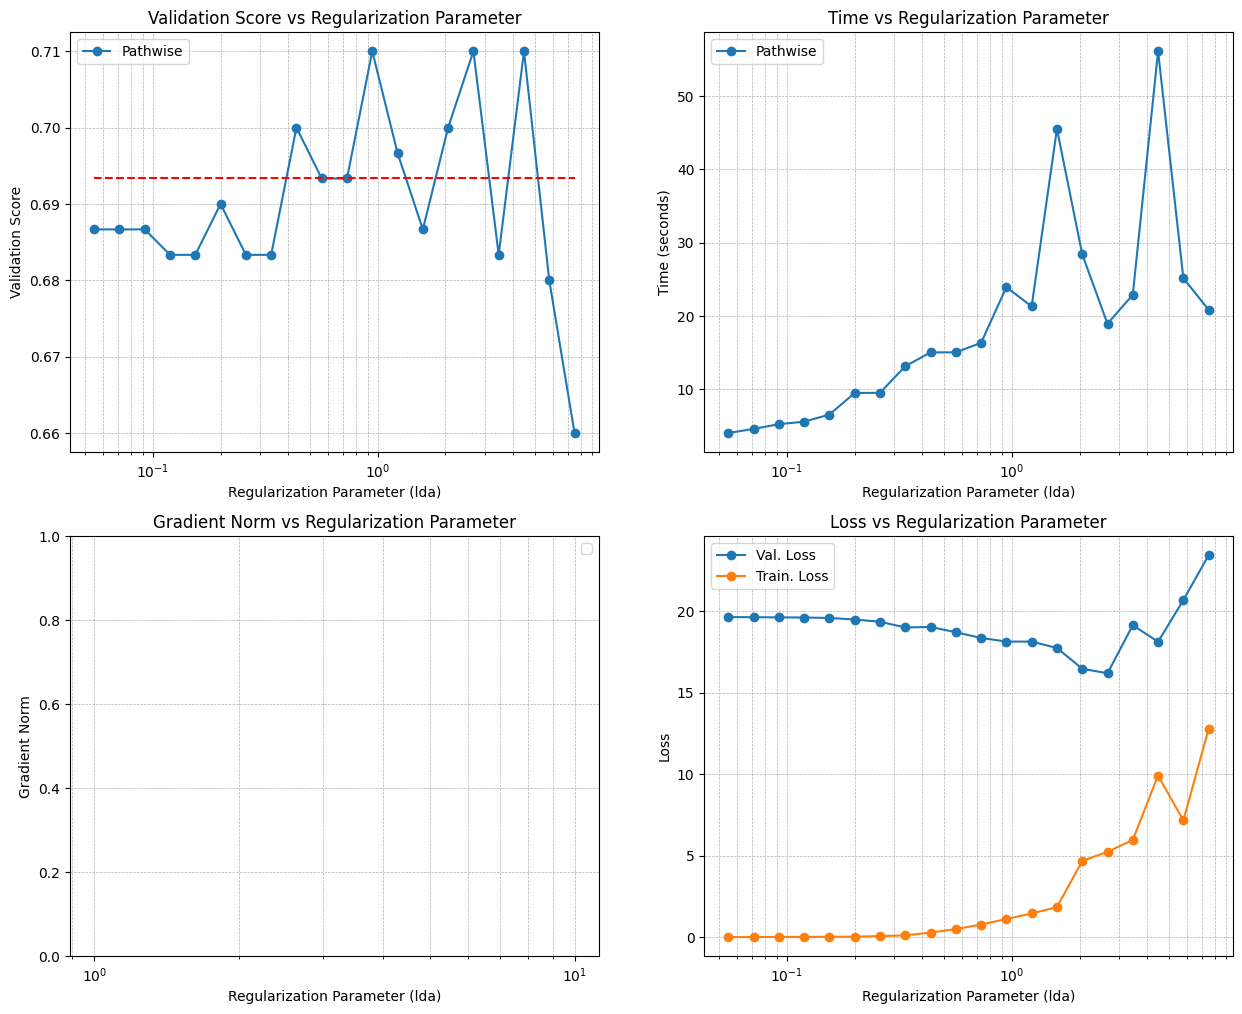

: 

In [ ]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
# axes[2].loglog(lda_range, results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

# axes[3].semilogx(results['lda'], results['U_sparsity'], label='Sparsity', marker='o')
# axes[3].semilogx(results['lda'], results['U_sparsity~'], label='Sparsity', marker='o')
axes[3].semilogx(results['lda'], results['v_loss'], label='Val. Loss', marker='o')
axes[3].semilogx(results['lda'], results['t_loss'], label='Train. Loss', marker='o')
axes[3].set_xlabel('Regularization Parameter (lda)')
# axes[3].set_ylabel('Sparsity')
axes[3].set_ylabel('Loss')
# axes[3].set_title('Cosine Similarity vs Regularization Parameter')
axes[3].set_title('Loss vs Regularization Parameter')
axes[3].legend()
axes[3].grid(True, which='both', linestyle='--', linewidth=0.5)

In [13]:
results['best_model'].hyperparameters
print(results['best_model']._v_score)

0.7266666666666667


In [7]:
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 1
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 100000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.8
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-5
lda_range = np.logspace(-4, 2.5, 14)[:-2]
search_results = []
best_models = []
best_model = deepcopy(model)
for mode in [1,2,3]:
    results = search_l1_path(
        best_model, mode, lda_range,
        X_train, y_train, X_val, y_val,
        rada_rgd_cfg,
        verbosity = 1
    )
    best_model = deepcopy(results['best_model'])
    best_models.append(best_model)
    search_results.append(results)


Running iteration 1/12 with lda=1.000e-04
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 3 iterations, 1.063 seconds.

Running iteration 2/12 with lda=3.162e-04
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 3 iterations, 0.996 seconds.

Running iteration 3/12 with lda=1.000e-03
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 5 iterations, 1.650 seconds.

Running iteration 4/12 with lda=3.162e-03
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 7 iterations, 2.317 seconds.

Running iteration 5/12 with lda=1.000e-02
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 9 iterations, 2.969 seconds.

Running iteration 6/12 with lda=3.162e-02
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 14 iterations, 4.623 seconds.

Running iteration 7/12 with lda=1.000e-01
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 20 iterations, 6.560 seconds.

Running iteration 8/12 with lda=3.162e-01
RADA

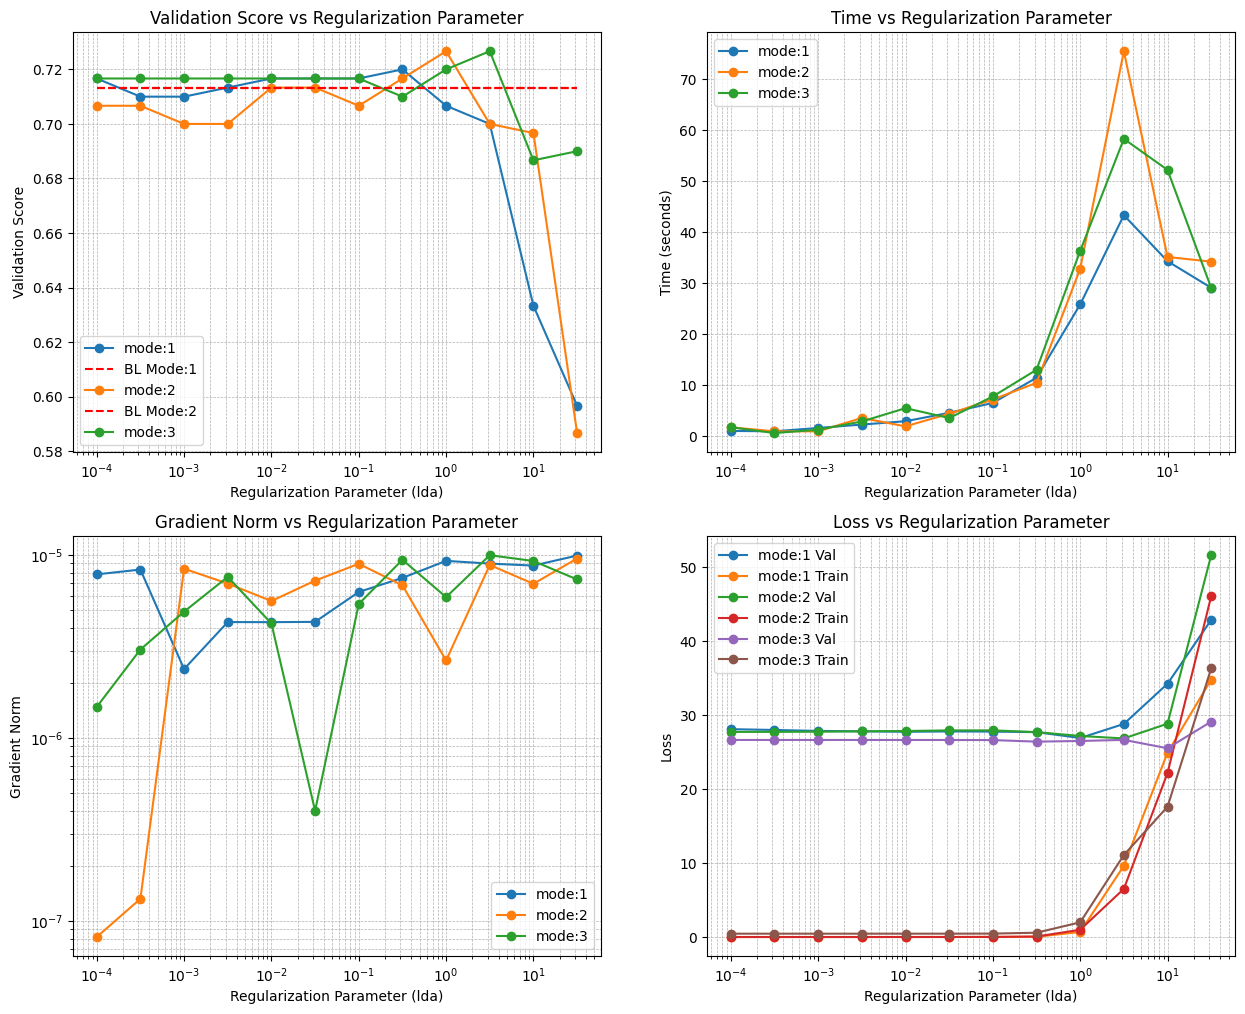

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for mode, results in enumerate(search_results):
    results['grad_norm'] = [float(x) for x in results['grad_norm']]
    results['v_loss'] = [float(x) for x in results['v_loss']]
    results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]

    axes[0].plot(results['lda'], results['v_score'], label=f'mode:{mode+1}', marker='o')
    axes[0].set_xscale('log')
    axes[0].set_xlabel('Regularization Parameter (lda)')
    axes[0].set_ylabel('Validation Score')
    axes[0].set_title('Validation Score vs Regularization Parameter')
    axes[0].legend()
    axes[0].hlines(results['baseline']['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
                colors='r', linestyles='dashed', label=f'BL Mode:{mode+1}')
    axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
    axes[1].plot(results['lda'], results['time'], label=f'mode:{mode+1}', marker='o')
    axes[1].set_xscale('log')
    axes[1].set_xlabel('Regularization Parameter (lda)')
    axes[1].set_ylabel('Time (seconds)')
    axes[1].set_title('Time vs Regularization Parameter')
    axes[1].legend()
    axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
    axes[2].loglog(lda_range, results['grad_norm'], label=f'mode:{mode+1}', marker='o')
    axes[2].set_xscale('log')
    axes[2].set_xlabel('Regularization Parameter (lda)')
    axes[2].set_ylabel('Gradient Norm')
    axes[2].set_title('Gradient Norm vs Regularization Parameter')
    axes[2].legend()
    axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

    axes[3].semilogx(results['lda'], results['v_loss'], label=f'mode:{mode+1} Val', marker='o')
    axes[3].semilogx(results['lda'], results['t_loss'], label=f'mode:{mode+1} Train', marker='o')
    axes[3].set_xlabel('Regularization Parameter (lda)')
    axes[3].set_ylabel('Loss')
    axes[3].set_title('Loss vs Regularization Parameter')
    axes[3].legend()
    axes[3].grid(True, which='both', linestyle='--', linewidth=0.5)

In [20]:
best_model = deepcopy(results['best_model'])
# best_model = deepcopy(search_results[0]['best_model'])
# best_model.ldas[0] =0.1316
# best_model.ldas[1] =0.1316
# best_model.ldas[2] =0.1316
best_model.verbosity = 1
best_model.max_time = 12309149449
best_model.max_it = 400
rada_cfg = conf.rada_rgd_cfg.copy()
best_model.verbosity = 2

rada_cfg.Tk= 100
rada_cfg.max_it = 100000 #rada_rgd_cfg.max_it * 20
rada_cfg.c1 = 0.8
rada_cfg.rho = 1.5 # 2.5
rada_cfg.eps = 1e-8
rada_cfg.R = 1e-8 #float(best_model.ldas[m-1]*27**0.5)
rada_cfg.beta1 = 0.1*27**0.5
rada_cfg.max_it = 10000
rada_cfg.verbosity = 0
best_model.subproblem_solvers[f'C'] = RADA_RGD(**rada_cfg)

for m in [1,2,3]:
    rada_cfg.Tk= 1
    rada_cfg.max_it = 100000 #rada_rgd_cfg.max_it * 20
    rada_cfg.c1 = 0.8
    rada_cfg.rho = 1.5 # 2.5
    rada_cfg.eps = 1e-8
    rada_cfg.R = float(best_model.ldas[m-1]*90**0.5)
    rada_cfg.beta1 = 0.1*30*3**0.5
    rada_cfg.max_it = 10000
    rada_cfg.verbosity = 0
    best_model.subproblem_solvers[f'U_{m}'] = RADA_RGD(**rada_cfg)
best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val, seed=0)


Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [4.468548331547404, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
  1          0.7622         0.6567       1.3878957795e+01    2.6718e-01       2.6718e-01       9.6136e-02       9.7584e-09       1.7782e-02     
  2          0.8311         0.6667       1.3788226985e+01    1.1349e+00       1.1349e+00       7.2472e-02       9.4436e-09       6.3100e-03     
  3          0.6889         0.5267       1.4074698405e+01    9

KeyboardInterrupt: 

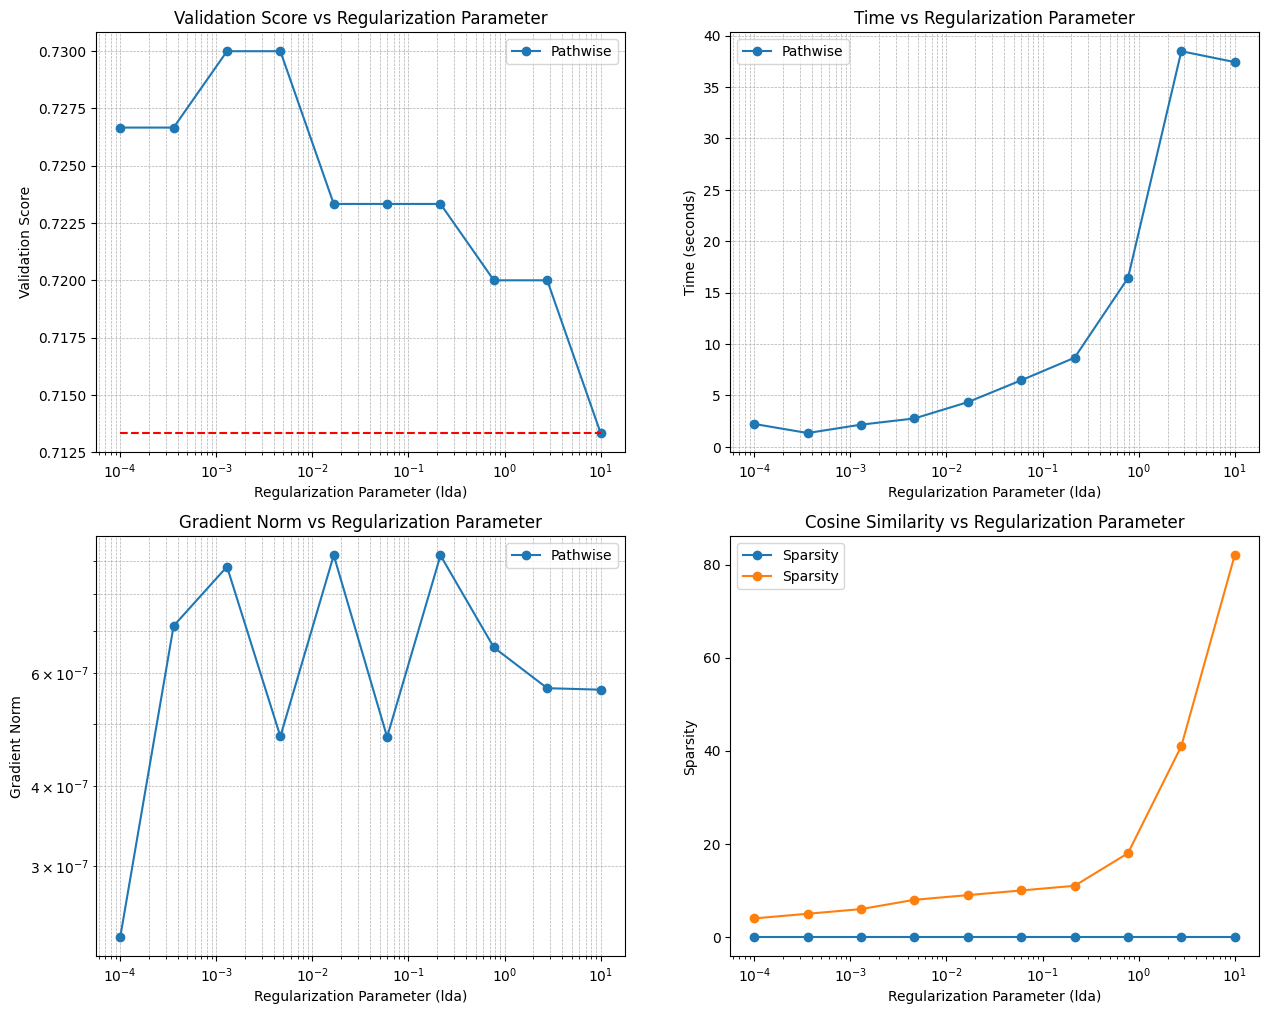

In [17]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

axes[3].semilogx(results['lda'], results['U_sparsity'], label='Sparsity', marker='o')
axes[3].semilogx(results['lda'], results['U_sparsity~'], label='Sparsity', marker='o')
axes[3].set_xlabel('Regularization Parameter (lda)')
axes[3].set_ylabel('Sparsity')
axes[3].set_title('Cosine Similarity vs Regularization Parameter')
axes[3].legend()

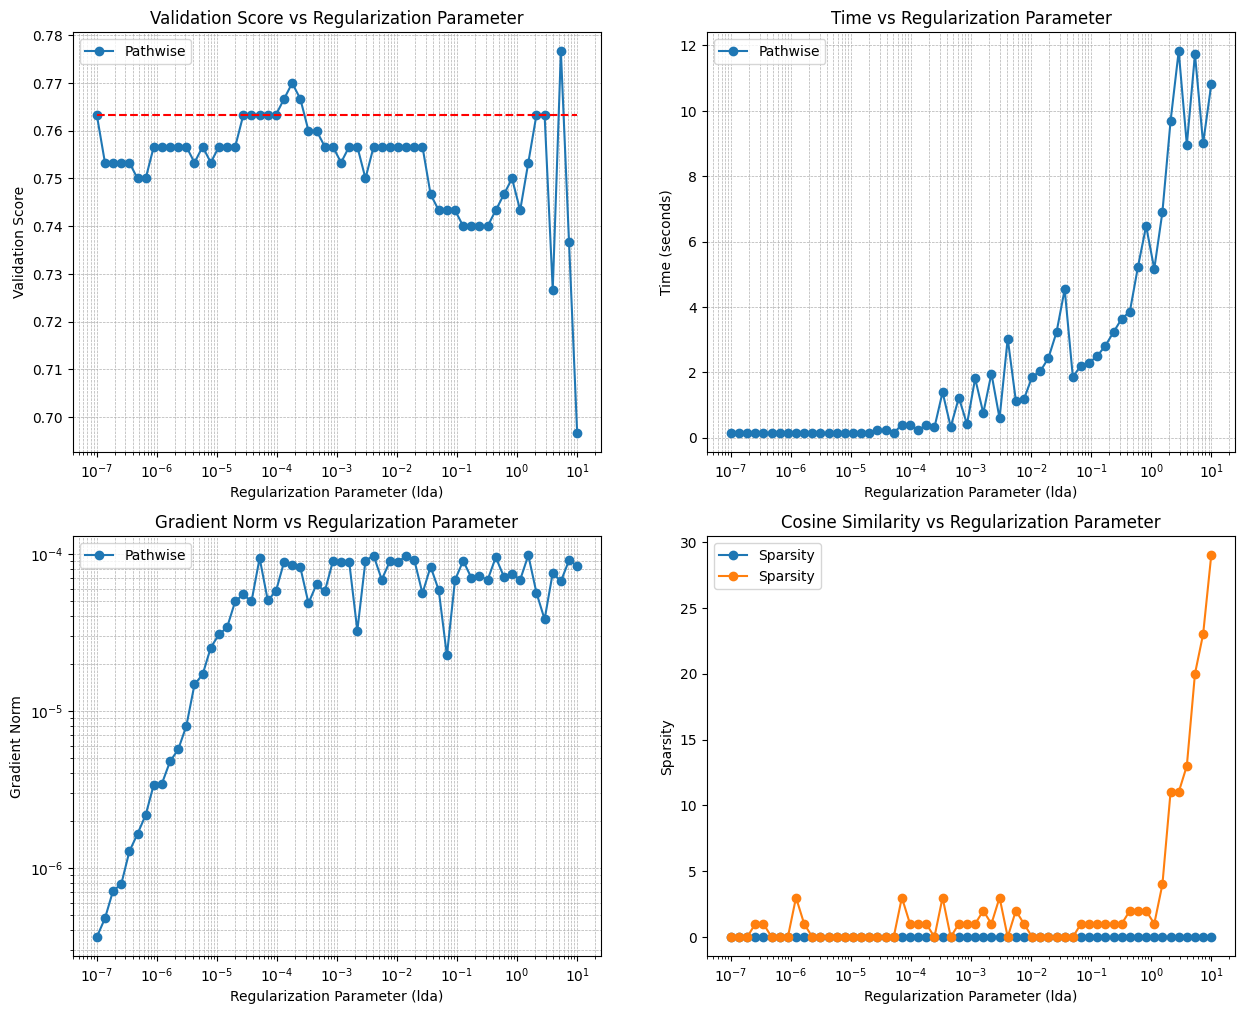

In [15]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

axes[3].semilogx(results['lda'], results['U_sparsity'], label='Sparsity', marker='o')
axes[3].semilogx(results['lda'], results['U_sparsity~'], label='Sparsity', marker='o')
axes[3].set_xlabel('Regularization Parameter (lda)')
axes[3].set_ylabel('Sparsity')
axes[3].set_title('Cosine Similarity vs Regularization Parameter')
axes[3].legend()

Best validation score: 0.7100 at lda=2.868e+00


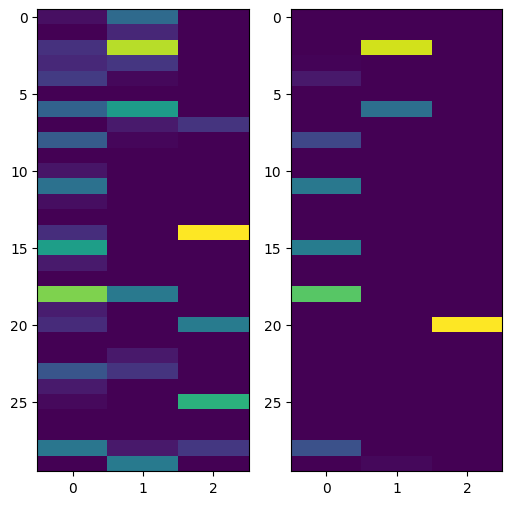

: 

In [ ]:
i_best = np.argmax(results['v_score'])
print(f"Best validation score: {results['v_score'][i_best]:.4f} at lda={results['lda'][i_best]:.3e}")
fig, axes = plt.subplots(1, 2, figsize=(6, 6))
# plt.hist(results['U_results'][i_best].cpu().numpy().ravel(), bins=20)
axes[0].imshow(results['U_results'][i_best].abs().cpu().numpy(), cmap='viridis', aspect='auto')
axes[1].imshow(results['U_results'][i_best+4].abs().cpu().numpy(), cmap='viridis', aspect='auto')

In [ ]:
def search_regularization_path(
    model: TuckerRegressorBCD,
    mode: int,
    reg_path: list[float],
    X, y, X_val, y_val,
    rada_cfg,
    verbosity=1,
    ):
    path_model = deepcopy(model)
    results = defaultdict(list)
    results['baseline'] = {
        't_score': model._t_score,
        'v_score': model._v_score,
        't_loss': model._t_loss,
        'v_loss': model._v_loss,
    }
    for i, lda in enumerate(reg_path):
        ts = perf_counter()
        path_model = deepcopy(path_model)
        if mode ==0:
            if verbosity:
                print(f"Running iteration {i+1}/{len(lda_range)} with tau={lda:.3e}")
            path_model.tau = lda
            dim = path_model.tucker_regressor.core.numel()
            problem, covariate_transform = path_model._initialize_C_subproblem(
                use_dloader=False,
                X=X,
                y=y,
                X_val=X_val,
                y_val=y_val,
                save_score_to_self=True,
            )
        else:
            if verbosity:
                print(f"Running iteration {i+1}/{len(lda_range)} with lda={lda:.3e}")
            path_model.ldas[mode-1] = lda
            dim = path_model.tucker_regressor.Us[mode-1].numel()
            problem, covariate_transform = path_model._initialize_U_subproblem(
                use_dloader=False,
                mode=mode,
                X=X,
                y=y,
                X_val=X_val,
                y_val=y_val,
                save_score_to_self=True,
            )
        rada_cfg.R = float(lda*dim**0.5)
        rada_cfg.beta1 = float(lda*dim)
        rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
        if mode == 0:
            rada_result = rada_rgd_solver.solve(
                problem,
                x0=path_model.tucker_regressor.core.detach().clone(),
                y0=path_model.solver_results[f'C'].point.y,
            )
            path_model.solver_results[f'C'] = rada_result
            path_model.tucker_regressor.core.requires_grad = False
            path_model.tucker_regressor.core.copy_(
                rada_result.point.x.data
                )
        else:
            rada_result = rada_rgd_solver.solve(
                problem,
                x0=path_model.tucker_regressor.Us[mode-1].detach().clone(),
                y0=path_model.solver_results[f'U_{mode}'].point.y,
            )
            path_model.solver_results[f'U_{mode}'] = rada_result
            path_model.tucker_regressor.Us[mode-1].requires_grad = False
            path_model.tucker_regressor.Us[mode-1].copy_(
                rada_result.point.x.data
            )



In [10]:

def search_ridge_path(
    base_model: TuckerRegressorBCD,
    ridge_path: list[float],
    X, y, X_val, y_val,
    rada_cfg,
    verbosity=1,
    ):
    path_model = deepcopy(base_model)
    results = defaultdict(list)
    results['baseline'] = {
        't_score': base_model._t_score,
        'v_score': base_model._v_score,
        't_loss': base_model._t_loss,
        'v_loss': base_model._v_loss,
    }

    for i, tau in enumerate(ridge_path):
        ts = perf_counter()
        path_model = deepcopy(path_model)
        if verbosity:
            print(f"Running iteration {i+1}/{len(ridge_path)} with tau={tau:.3e}")
        path_model.tau = tau
        dim = path_model.tucker_regressor.core.numel()
        problem, covariate_transform = path_model._initialize_C_subproblem(
            use_dloader=False,
            X=X,
            y=y
        )
        lda_core = path_model.lda_core
        rada_cfg.R = float(lda_core*dim**0.5)
        rada_cfg.beta1 = 0.01*dim # float(lda*dim)/100
        rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
        rada_result = rada_rgd_solver.solve(
            problem,
            x0=path_model.tucker_regressor.core.detach().clone(),
            # y0=path_model.solver_results['C'].point.y,
        )
        path_model.solver_results['C'] = rada_result
        path_model.tucker_regressor.core.requires_grad = False
        path_model.tucker_regressor.core.copy_(
            rada_result.point.x.data
        )

        results['results'].append(rada_result.point.x.data.clone().detach())
        results['sparsity'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.data != 0).sum()))
        results['sparsity~'].append(float(rada_result.point.x.data.numel() - (rada_result.point.x.abs() > 1e-6).sum()))
        results['time'].append(perf_counter() - ts)
        results['grad_norm'].append(float(rada_result.gradient_norm))
        results['tau'].append(float(tau))
        results['lda_core'].append(float(lda_core))

        with torch.no_grad():
            X_prime = covariate_transform(X)
            eta = path_model.tucker_regressor.functional_core(
                core=rada_result.point.x,
                x=X_prime)
            train_loss = path_model.tucker_regressor.loss_fn(eta, y)
            train_score = path_model.tucker_regressor.score(eta, y)

            X_val_prime = covariate_transform(X_val)
            eta = path_model.tucker_regressor.functional_core(
                core=rada_result.point.x,
                x=X_val_prime)
            val_loss = path_model.tucker_regressor.loss_fn(eta, y_val)
            val_score = path_model.tucker_regressor.score(eta, y_val)

        results['v_score'].append(val_score)
        results['t_score'].append(train_score)
        results['v_loss'].append(val_loss)
        results['t_loss'].append(train_loss)
    return results


In [11]:
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 1
rada_rgd_cfg.max_it = 10000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-8
tau_range = np.logspace(-6, 3, 60)
results = search_ridge_path(
    model, tau_range,
    X_train, y_train, X_val, y_val,
    rada_rgd_cfg,
    verbosity = 1
)

Running iteration 1/60 with tau=1.000e-06
Running iteration 2/60 with tau=1.421e-06
Running iteration 3/60 with tau=2.019e-06
Running iteration 4/60 with tau=2.868e-06
Running iteration 5/60 with tau=4.075e-06
Running iteration 6/60 with tau=5.790e-06
Running iteration 7/60 with tau=8.227e-06
Running iteration 8/60 with tau=1.169e-05
Running iteration 9/60 with tau=1.661e-05
Running iteration 10/60 with tau=2.360e-05
Running iteration 11/60 with tau=3.353e-05
Running iteration 12/60 with tau=4.764e-05
Running iteration 13/60 with tau=6.769e-05
Running iteration 14/60 with tau=9.617e-05
Running iteration 15/60 with tau=1.366e-04
Running iteration 16/60 with tau=1.941e-04
Running iteration 17/60 with tau=2.759e-04
Running iteration 18/60 with tau=3.919e-04
Running iteration 19/60 with tau=5.569e-04
Running iteration 20/60 with tau=7.912e-04
Running iteration 21/60 with tau=1.124e-03
Running iteration 22/60 with tau=1.597e-03
Running iteration 23/60 with tau=2.270e-03
Running iteration 24

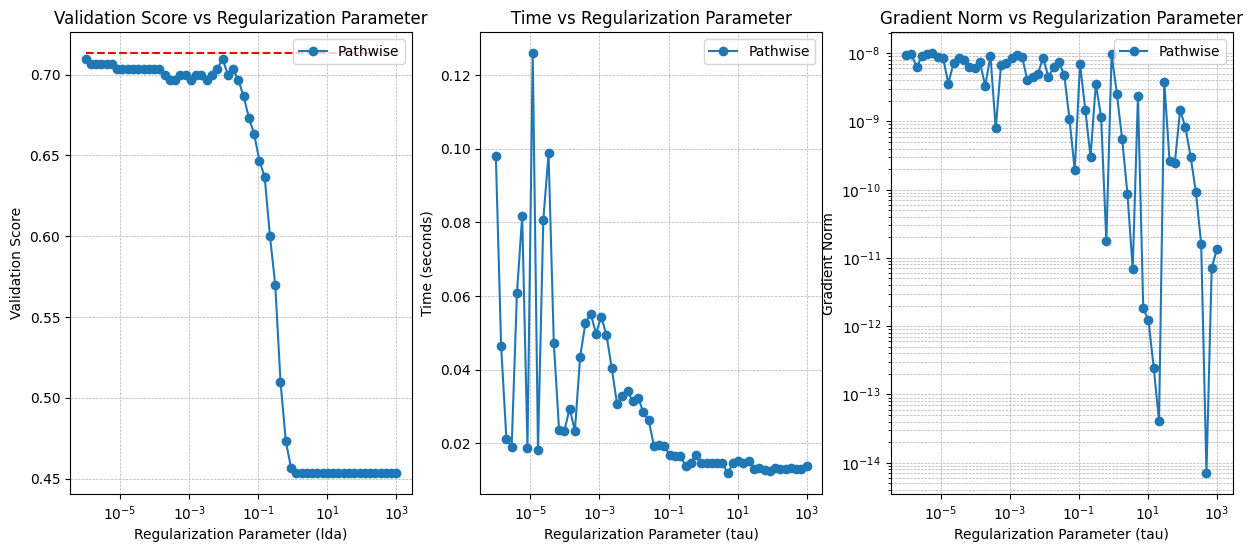

: 

In [ ]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes = axes.flatten()
axes[0].plot(results['tau'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'],
               xmin=results['tau'][0], xmax=results['tau'][-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['tau'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (tau)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(results['tau'], results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (tau)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

In [12]:
from copy import deepcopy
from collections import defaultdict
from time import perf_counter
from typing import overload

from torch.utils.data import Dataset

from t_regs.utils import printer
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.models.regression.tucker_nn_regressor import (
    TuckerRegressor,
    TuckerCovariateTransform
    )


class TuckerBCDRegularizerPathStudy:

    def __init__(
        self,
        parameter: str,
        reg_path: list[float],
        rada_cfg: dict[str, Any],
        mode: Optional[int] = None,
        verbosity: Optional[int] = 1
        ):
        self.parameter = parameter
        self.reg_path = reg_path
        self.rada_cfg = rada_cfg
        self.mode = mode
        self.verbosity = verbosity
        self.log = None

    @overload
    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        X: torch.Tensor,
        y: torch.Tensor,
        X_val: torch.Tensor,
        y_val: torch.Tensor,
        ):
        pass

    @overload
    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        dataset: Dataset,
        val_dataset: Dataset,
        ):
        pass

    def __call__(
        self,
        base_model: TuckerRegressorBCD,
        **kwargs
        ):
        printer = self._init_printer(base_model)
        printer.print_header()
        X = kwargs.get('X', None)
        y = kwargs.get('y', None)
        X_val = kwargs.get('X_val', None)
        y_val = kwargs.get('y_val', None)
        dataset = kwargs.get('dataset', None)
        val_dataset = kwargs.get('val_dataset', None)
        use_dloader = X is None
        if base_model._t_loss is None:
            if use_dloader:
                base_model.fit(dataset, val_dataset=val_dataset)
            else:
                base_model.fit(X, y, X_val=X_val, y_val=y_val)
        self._init_log(base_model)
        path_model = deepcopy(base_model)

        best_model = deepcopy(base_model)
        best_score = best_model._v_score
        best_model_reg_params = {
            'tau': best_model.tau,
            'lda_core': best_model.lda_core,
            'thetas': best_model.thetas,
            'ldas': best_model.ldas,
        }
        rada_cfg = deepcopy(self.rada_cfg)
        for i, reg_param in enumerate(self.reg_path):
            ts = perf_counter()
            # path_model = deepcopy(path_model)
            if self.parameter == 'ldas' or self.parameter == 'thetas':
                mode = self.mode
                dim = path_model.tucker_regressor.Us[mode-1].numel()
                if self.parameter == 'ldas':
                    path_model.ldas[mode-1] = reg_param
                else:
                    path_model.thetas[mode-1] = reg_param
                lda = path_model.ldas[mode-1]
                y0 = path_model.solver_results[f'U_{mode}'].point.y if i != 0 else None
                problem, cov_transform = path_model._initialize_U_subproblem(
                    use_dloader=False,
                    mode=mode,
                    X=X,
                    y=y,
                    X_val=X_val,
                    y_val=y_val,
                    save_score_to_self=True,
                )
                rada_cfg.R = float(lda*dim**0.5)
                rada_cfg.beta1 = 0.1*30*3**0.5
                rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
                path_model.subproblem_solvers[f'U_{mode}'] = rada_rgd_solver
                rada_result = rada_rgd_solver.solve(
                    problem,
                    x0=path_model.tucker_regressor.Us[mode-1].detach().clone(),
                    y0=path_model.solver_results[f'U_{mode}'].point.y,
                )
                path_model.solver_results[f'U_{mode}'] = rada_result
                path_model.tucker_regressor.Us[mode-1].requires_grad = False
                path_model.tucker_regressor.Us[mode-1].copy_(
                    rada_result.point.x.data
                )
                val_score = float(path_model._v_score)
                train_score = float(path_model._t_score)
                val_loss = float(path_model._v_loss)
                train_loss = float(path_model._t_loss)
                if val_score >= best_score:
                    best_model = deepcopy(path_model)
                    best_score = val_score
                    best_model_reg_params = {
                        'tau': best_model.tau,
                        'lda_core': best_model.lda_core,
                        'thetas': best_model.thetas,
                        'ldas': best_model.ldas,
                    }
                    self.log['improved'] = True
            elif self.parameter == 'tau' or self.parameter == 'lda_core':
                if self.parameter == 'tau':
                    path_model.tau = reg_param
                else:
                    path_model.lda_core = reg_param
                dim = path_model.tucker_regressor.core.numel()
                problem, cov_transform = path_model._initialize_C_subproblem(
                    use_dloader=use_dloader,
                    X=X,
                    y=y,
                    # X_val=X_val,
                    # y_val=y_val,
                    dataset=dataset
                )
                rada_cfg = deepcopy(self.rada_cfg)
                lda_core = path_model.lda_core
                rada_cfg.R = float(lda_core*dim**0.5)
                # rada_cfg.beta1 = 0.01*dim # float(lda*dim)/100
                rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
                path_model.subproblem_solvers['C'] = rada_rgd_solver
                rada_result = rada_rgd_solver.solve(
                    problem,
                    x0=path_model.tucker_regressor.core.detach().clone(),
                    # y0=path_model.solver_results['C'].point.y,
                )
                path_model.solver_results['C'] = rada_result
                path_model.tucker_regressor.core.requires_grad = False
                path_model.tucker_regressor.core.copy_(
                    rada_result.point.x.data
                )

                with torch.no_grad():
                    X_prime = cov_transform(X)
                    eta = path_model.tucker_regressor.functional_core(
                        core = rada_result.point.x,
                        x = X_prime
                        )
                    train_loss= float(
                        path_model.tucker_regressor.loss_fn(eta, y)
                        )
                    train_score = float(
                        path_model.tucker_regressor.score(eta, y)
                        )

                    X_val_prime = cov_transform(X_val)
                    eta = path_model.tucker_regressor.functional_core(
                        core=rada_result.point.x,
                        x=X_val_prime
                        )
                    val_loss = float(
                        path_model.tucker_regressor.loss_fn(eta, y_val)
                        )
                    val_score=float(path_model.tucker_regressor.score(eta, y_val))
                path_model._v_score = val_score
                path_model._v_loss = val_loss
                path_model._t_score = train_score
                path_model._t_loss = train_loss

            else:
                raise ValueError(f"Unknown parameter: {self.parameter}")

            grad_norm = float(rada_result.gradient_norm)
            tspent = perf_counter() - ts
            num_iter = rada_result.iterations
            term_reason = rada_result.stopping_criterion
            columns = [i, reg_param, train_score, val_score, train_loss,
                       val_loss, grad_norm, tspent, num_iter, term_reason]
            printer.print_row(columns)

            self._add_log_entry(*columns)
            if val_score >= best_score:
                best_model = deepcopy(path_model)
                best_score = val_score
                best_model_reg_params = {
                    'tau': best_model.tau,
                    'lda_core': best_model.lda_core,
                    'thetas': best_model.thetas,
                    'ldas': best_model.ldas,
                }
                self.log['improved'] = True

        return best_model, best_model_reg_params, self.log

    def _init_printer(self, base_model: TuckerRegressorBCD):
        if self.verbosity:
            msg = f"Starting regularization path study for parameter: {self.parameter}"
            msg += f" mode: {self.mode}" if self.mode is not None else ""
            print(msg)
            # TODO: Output base model hyperparameters & baseline scores.
            if self.verbosity >=3:
                print(f"RADA RGD configuration: {self.rada_cfg}")
            if self.verbosity >= 2:
                print(f"Base model configuration:")
                pprint(base_model.hyperparameters)
            iteration_format_length = int(np.log10(len(self.reg_path))) + 1
            lent = int(np.log10(self.rada_cfg.max_it)) + 1
            columns = [
                ("Iteration", f"{iteration_format_length}d"),
                (self.parameter, ".4e"),
                ("Train Score", ".4f"),
                ("Val Score", ".4f"),
                ("Train Loss", ".4e"),
                ("Val Loss", ".4e"),
                ("Grad Norm", ".4e"),
                ("Time (s)", ".2f"),
                ("Num. Iter.", f"{lent}d"),
                ("Termination Reason", ""),
            ]
            column_printer = printer.ColumnPrinter(columns=columns)
        else:
            column_printer = printer.VoidPrinter()
        return column_printer

    def _init_log(self, base_model: TuckerRegressorBCD):
        self.log = {
            'baseline': {
                'train_score': float(base_model._t_score),
                'val_score': float(base_model._v_score),
                'train_loss': float(base_model._t_loss),
                'val_loss': float(base_model._v_loss),
            },
            'results': defaultdict(list),
            'param': self.parameter,
            'mode': self.mode,
            'reg_path': self.reg_path,
            'improved': False,
        }

    def _add_log_entry(self,
        iteration, reg_param, train_score, val_score, train_loss,
        val_loss, grad_norm, tspent, num_iter, term_reason,
        **kwargs
        ):
        self.log['results']['iteration'].append(iteration)
        self.log['results']['reg_param'].append(reg_param)
        self.log['results']['train_score'].append(train_score)
        self.log['results']['val_score'].append(val_score)
        self.log['results']['train_loss'].append(train_loss)
        self.log['results']['val_loss'].append(val_loss)
        self.log['results']['grad_norm'].append(grad_norm)
        self.log['results']['time'].append(tspent)
        self.log['results']['num_iter'].append(num_iter)
        if self.verbosity > 1:
            self.log['results']['term_reason'].append(term_reason)
        for key, value in kwargs.items():
            self.log['iterations'][key].append(value)

    def plot(self, extra_metrics: list[str] = []):
        num_metrics = 1+len(extra_metrics)
        fig, axes = plt.subplots(1, num_metrics, figsize=(7*num_metrics, 6))
        if num_metrics == 1:
            axes = [axes]
        axes[0].semilogx(self.log['results']['reg_param'],
                         self.log['results']['val_score'],
                         marker='o', label='Validation')
        axes[0].semilogx(self.log['results']['reg_param'],
                         self.log['results']['train_score'],
                         marker='o', label='Training')
        axes[0].set_xscale('log')
        axes[0].set_xlabel(f'Regularization Parameter ({self.parameter})')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Score vs Regularization Parameter')
        axes[0].legend()
        axes[0].hlines(self.log['baseline']['val_score'],
                    xmin=self.log['reg_path'][0],
                    xmax=self.log['reg_path'][-1], 
                    colors='r', linestyles='dashed',
                    label='Baseline Validation Score')
        axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)

        for i in range(1, num_metrics):
            mname = extra_metrics[i-1]
            axes[i].semilogx(self.log['results']['reg_param'],
                         self.log['results'][mname], marker='o')
            axes[i].set_xscale('log')
            axes[i].set_xlabel(f'Regularization Parameter ({self.parameter})')
            axes[i].set_ylabel(mname)
            axes[i].set_title(f'{mname} vs Regularization Parameter')
            axes[i].legend()
            axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)
        return fig, axes

In [13]:
rada_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 10
rada_rgd_cfg.max_it = 250 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 4 # 2.5
rada_rgd_cfg.eps = 1.0e-8
rada_rgd_cfg.max_function_evals = rada_rgd_cfg.max_it * rada_rgd_cfg.Tk * 5
rada_rgd_cfg.beta1 = 1e15

parameter: str = 'ldas' # 'tau' 
reg_path: list[float] = [float(i) for i in np.logspace(-8, 5, 40)]
mode: Optional[int] = 1 # None # 1
verbosity: Optional[int] = 1

pstudy = TuckerBCDRegularizerPathStudy(
    parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
    )

best_model, best_hparams, log = pstudy(
    model,
    X=X_train,
    y=y_train,
    X_val=X_val,
    y_val=y_val
    )

Starting regularization path study for parameter: ldas mode: 1
Iteration    ldas          Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    


 0           1.0000e-08    1.0000         0.7167       6.6701e-08    2.7298e+01    3.4703e-10    2.61         84           Terminated - eps-RGS point reached after 84 iterations, 2.607 seconds.
 1           2.1544e-08    1.0000         0.7167       6.6744e-08    2.7301e+01    4.4790e-10    3.77        122           Terminated - eps-RGS point reached after 122 iterations, 3.769 seconds.
 2           4.6416e-08    1.0000         0.7167       6.6946e-08    2.7305e+01    8.8298e-10    4.62        149           Terminated - eps-RGS point reached after 149 iterations, 4.612 seconds.
 3           1.0000e-07    1.0000         0.7167       6.7895e-08    2.7316e+01    1.4908e-09    5.60        181           Terminated - eps-RGS point reached after 181 iterations, 5.601 seconds.
 4           2.1544e-07    1.0000         0.7167       7.2311e-08    2.7341e+01    2.1592e-09    7.60        245           Terminated - eps-RGS point reached after 245 iterations, 7.597 seconds.
 5           4.6416e-07   

(<Figure size 700x600 with 1 Axes>,
 [<Axes: title={'center': 'Score vs Regularization Parameter'}, xlabel='Regularization Parameter (ldas)', ylabel='Score'>])

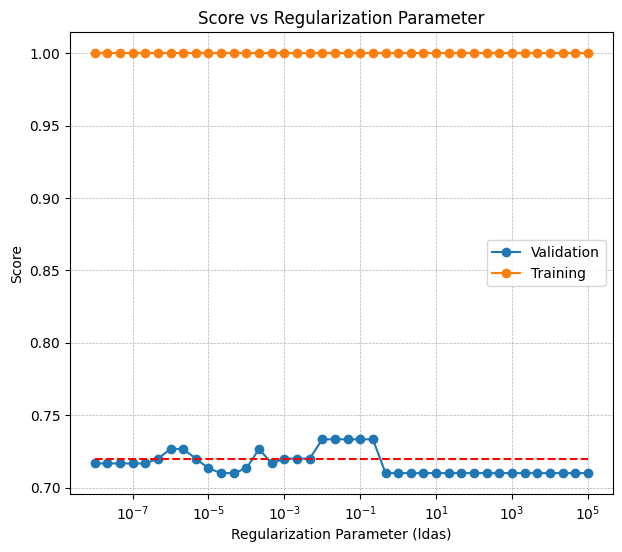

In [15]:
pstudy.plot()

In [12]:
rada_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 1000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 2.0 #1.5 # 2.5
rada_rgd_cfg.eps = 1e-6
model.min_gradient_norm = rada_rgd_cfg.eps


best_model = deepcopy(model)
best_val_score = model._v_score
parameter: str = 'tau'
reg_path: list[float] = [float(i) for i in np.logspace(-7, 4, 30)]
mode = None # 1
verbosity = 2

print(f"Baseline val score: {best_val_score:.4f}")
pstudy = TuckerBCDRegularizerPathStudy(
    parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
    )

best_model, best_hparams, log = pstudy(
    best_model,
    X=X_train,
    y=y_train,
    X_val=X_val,
    y_val=y_val
    )
if best_model._v_score >= model._v_score:
    print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
    best_val_score = best_model._v_score
    
# pprint(best_model.hyperparameters)
best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)
best_val_score = best_model._v_score


# for mode in [1,2,3]:
#     rada_rgd_cfg = conf.rada_rgd_cfg.copy()
#     rada_rgd_cfg.verbosity = 2
#     rada_rgd_cfg.Tk= 10
#     rada_rgd_cfg.max_it = 2000 #rada_rgd_cfg.max_it * 20
#     rada_rgd_cfg.c1 = 0.1
#     rada_rgd_cfg.rho = 2.5 # 2.5
#     rada_rgd_cfg.eps = 1.0e-8
#     rada_rgd_cfg.max_function_evals = rada_rgd_cfg.max_it * rada_rgd_cfg.Tk * 5
#     rada_rgd_cfg.beta1 = 1e6

#     parameter: str = 'ldas'
#     reg_path: list[float] = [float(i) for i in np.logspace(-6, 6, 37)]
#     mode = mode # 1
#     verbosity = 2
#     print(f"Baseline val score: {best_val_score:.4f}")
#     pstudy = TuckerBCDRegularizerPathStudy(
#         parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
#         )

#     best_model, best_hparams, log = pstudy(
#         best_model,
#         X=X_train,
#         y=y_train,
#         X_val=X_val,
#         y_val=y_val
#         )
#     if log['improved']:
#         print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
#         best_val_score = best_model._v_score
    
#     best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)

Baseline val score: 0.7067
Starting regularization path study for parameter: tau
Base model configuration:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    tau           Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    
 0           1.0000e-07    1.0000         0.7067       4.2390e-04    7.3379e+03    1.5179e-13    0.28           1          Terminated - eps-RGS point reached after 1 iterations, 0.269 seconds.
 1           2.3950e-07    1.0000         0.7067       9.4684e-04    6.8701e+03    2.9785e-14    0.26           1          Termi

In [53]:
# mid_model = deepcopy(best_model)
best_model = deepcopy(mid_model)

In [ ]:
# mid_model = deepcopy(best_model)
# best_model = deepcopy(mid_model)

for mode in [1,2,3]:
    rada_rgd_cfg = conf.rada_rgd_cfg.copy()
    rada_rgd_cfg.verbosity = 0
    rada_rgd_cfg.Tk= 5
    rada_rgd_cfg.max_it = 2000 #rada_rgd_cfg.max_it * 20
    rada_rgd_cfg.c1 = 0.0001
    rada_rgd_cfg.rho = 2.0 # 2.5
    rada_rgd_cfg.eps = 1.0e-8
    rada_rgd_cfg.max_function_evals = rada_rgd_cfg.max_it * rada_rgd_cfg.Tk * 5
    rada_rgd_cfg.beta1 = 30*1.47*0.5*0.01

    parameter: str = 'ldas'
    reg_path: list[float] = [float(i) for i in np.logspace(-5, 4, 15)]
    mode = mode # 1
    verbosity = 2
    print(f"Baseline val score: {best_val_score:.4f}")
    pstudy = TuckerBCDRegularizerPathStudy(
        parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
        )

    best_model, best_hparams, log = pstudy(
        best_model,
        X=X_train,
        y=y_train,
        X_val=X_val,
        y_val=y_val
        )
    print(best_model._v_score)
    if log['improved']:
        print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
        best_val_score = best_model._v_score
    
    best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)

Baseline val score: 0.7100
Starting regularization path study for parameter: ldas mode: 1
Base model configuration:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.6723357536499335,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    ldas          Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    
 0           1.0000e-05    1.0000         0.7100       4.6725e-02    1.2914e+00    5.0332e-09    0.39           8          Terminated - eps-RGS point reached after 8 iterations, 0.321 seconds.
 1           4.3940e-05    1.0000         0.7100       4.6725e-02    1.2914e+00    4.9853e-09    0.30   

KeyboardInterrupt: 

In [ ]:
best_model.max_time = 1200

rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 1000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 2.0 #1.5 # 2.5
rada_rgd_cfg.eps = 1e-6
model.min_gradient_norm = rada_rgd_cfg.eps

parameter: str = 'tau'
reg_path: list[float] = [float(i) for i in np.logspace(-7, 4, 30)]

print(f"Baseline val score: {best_val_score:.4f}")
pstudy = TuckerBCDRegularizerPathStudy(
    parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
    )

best_model, best_hparams, log = pstudy(
    best_model,
    X=X_train,
    y=y_train,
    X_val=X_val,
    y_val=y_val
    )
if best_model._v_score >= model._v_score:
    print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
    best_val_score = best_model._v_score
    
# pprint(best_model.hyperparameters)
best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)
best_val_score = best_model._v_score


Baseline val score: 0.7100
Starting regularization path study for parameter: tau
Base model configuration:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.6723357536499335,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    tau           Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    
 0           1.0000e-07    1.0000         0.7167       5.1540e-03    3.0296e+03    8.3772e-07    0.45           1          Terminated - eps-RGS point reached after 1 iterations, 0.425 seconds.
 1           2.3950e-07    1.0000         0.7200       3.0729e-04    4.0038e+03    2.3501e-12    0.43           1

KeyboardInterrupt: 

In [5]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')
model_cfg = conf.model_cfg.copy()
conf.data.data_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [8, 8, 8]
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)

conf.model_cfg.regressor.feature_ranks[0] = 3
conf.model_cfg.regressor.feature_ranks[1] = 3
conf.model_cfg.regressor.feature_ranks[2] = 3
conf.model_cfg.verbosity = 2
conf.model_cfg.max_it= 100
conf.model_cfg.max_time= 100
conf.rada_rgd_cfg.Tk = 20
pprint(conf.model_cfg)


# torch.manual_seed(1)
data = get_data(conf.data)
model = get_model(conf.model_cfg, 'cuda:2')
data['X'] = data['X'].to(model.device)
data['y'] = data['y'].to(model.device)
X_train, X_val = data['X'][300:], data['X'][:300]
y_train, y_val = data['y'][300:].reshape(-1, 1), data['y'][:300].reshape(-1, 1)
model.fit(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val
)

{'regression_type': 'logistic', 'tensor_type': 'low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None], 'data_type': 'sparse_low_tucker_rank', 'cardinalities': [8, 8, 8]}
{'model_name': 'LR-Tucker', 'regressor': {'regression_type': 'logistic', 'feature_dims': '${data.dims}', 'feature_ranks': [3, 3, 3], 'feature_manifolds': ['${Steifel:${..feature_dims[0]}, ${..feature_ranks[0]}, ${...device}}', '${Steifel:${..feature_dims[1]}, ${..feature_ranks[1]}, ${...device}}', '${Steifel:${..feature_dims[2]}, ${..feature_ranks[2]}, ${...device}}']}, 'tau': 0.0, 'ldas': [0.0, 0.0, 0.0], 'lda_core': 0.0, 'thetas': [0.0, 0.0, 0.0], 'Ds': None, 'Ls': [None, None, None], 'subproblem_solvers': {'U_1': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[0]},${mul:${data.dims[0]},${..regressor.feature_ranks[0]}}}', 'U_2': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[1]},${mul:${data.dims[1]},${..regressor.feature_ranks[1]}}}', 'U_3

In [17]:
rada_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 0
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it = 1000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.01
rada_rgd_cfg.rho = 1.5 #1.5 # 2.5
rada_rgd_cfg.eps = 1e-8
rada_rgd_cfg.beta1 = 30*3**0.5*0.1
model.min_gradient_norm = rada_rgd_cfg.eps


best_model = deepcopy(model)
best_val_score = model._v_score
parameter: str = 'tau'
reg_path: list[float] = [float(i) for i in np.logspace(-7, 4, 60)]
mode = None # 1
verbosity = 2

print(f"Baseline val score: {best_val_score:.4f}")
pstudy = TuckerBCDRegularizerPathStudy(
    parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
    )

best_model, best_hparams, ridge_log = pstudy(
    best_model,
    X=X_train,
    y=y_train,
    X_val=X_val,
    y_val=y_val
    )
if best_model._v_score >= model._v_score:
    print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
    best_val_score = best_model._v_score
    
# pprint(best_model.hyperparameters)
best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)
best_val_score = best_model._v_score
ridge_model = deepcopy(best_model)

Baseline val score: 0.7200
Starting regularization path study for parameter: tau
Base model configuration:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    tau           Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    
 0           1.0000e-07    1.0000         0.7200       4.7615e-04    7.0527e+03    2.4858e-17    0.28           1          Terminated - eps-RGS point reached after 1 iterations, 0.276 seconds.
 1           1.5362e-07    1.0000         0.7200       7.0781e-04    6.8291e+03    1.5189e-18    0.23           1          Termi

(<Figure size 700x600 with 1 Axes>,
 [<Axes: title={'center': 'Score vs Regularization Parameter'}, xlabel='Regularization Parameter (tau)', ylabel='Score'>])

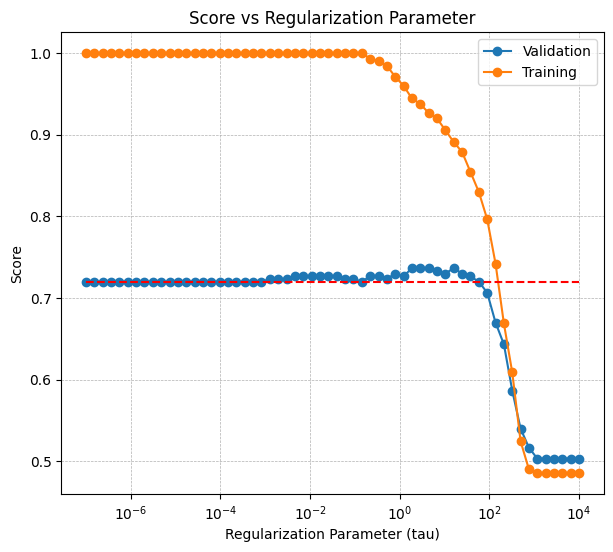

In [18]:
pstudy.plot()

In [19]:
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 1
rada_rgd_cfg.Tk= 25
rada_rgd_cfg.max_it = 10000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.1
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-6
lda_range = np.logspace(-7, 1, 60)
results = search_l1_path(
    ridge_model, 1, lda_range,
    X_train, y_train, X_val, y_val,
    rada_rgd_cfg,
    verbosity = 1
)

Running iteration 1/60 with lda=1.000e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.100 seconds.

Running iteration 2/60 with lda=1.366e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.081 seconds.

Running iteration 3/60 with lda=1.867e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.079 seconds.

Running iteration 4/60 with lda=2.551e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.080 seconds.

Running iteration 5/60 with lda=3.486e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.081 seconds.

Running iteration 6/60 with lda=4.764e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.080 seconds.

Running iteration 7/60 with lda=6.510e-07
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.081 seconds.

Running iteration 8/60 with lda=8.895e-07
RADA R

In [22]:
results

defaultdict(list,
            {'baseline': {'t_score': 1.0,
              'v_score': 0.72,
              't_loss': 7.629796940833742e-08,
              'v_loss': tensor(27.2794, device='cuda:2', dtype=torch.float64)},
             'U_results': [tensor([[-0.0305,  0.2164,  0.1136],
                      [-0.1317,  0.1106, -0.0711],
                      [-0.0363,  0.0562, -0.2325],
                      [ 0.1387,  0.0049,  0.0380],
                      [-0.1692, -0.0273, -0.2238],
                      [-0.1071,  0.1769, -0.1020],
                      [ 0.1304,  0.0593, -0.0971],
                      [ 0.0899, -0.0863,  0.4128],
                      [-0.0821, -0.2325,  0.1012],
                      [-0.0030, -0.1918,  0.0526],
                      [ 0.0814, -0.0040, -0.2394],
                      [-0.0431,  0.1787,  0.1427],
                      [ 0.0608, -0.0249, -0.0297],
                      [ 0.1197, -0.0865,  0.2656],
                      [-0.2989, -0.1368,  0.0871],
    

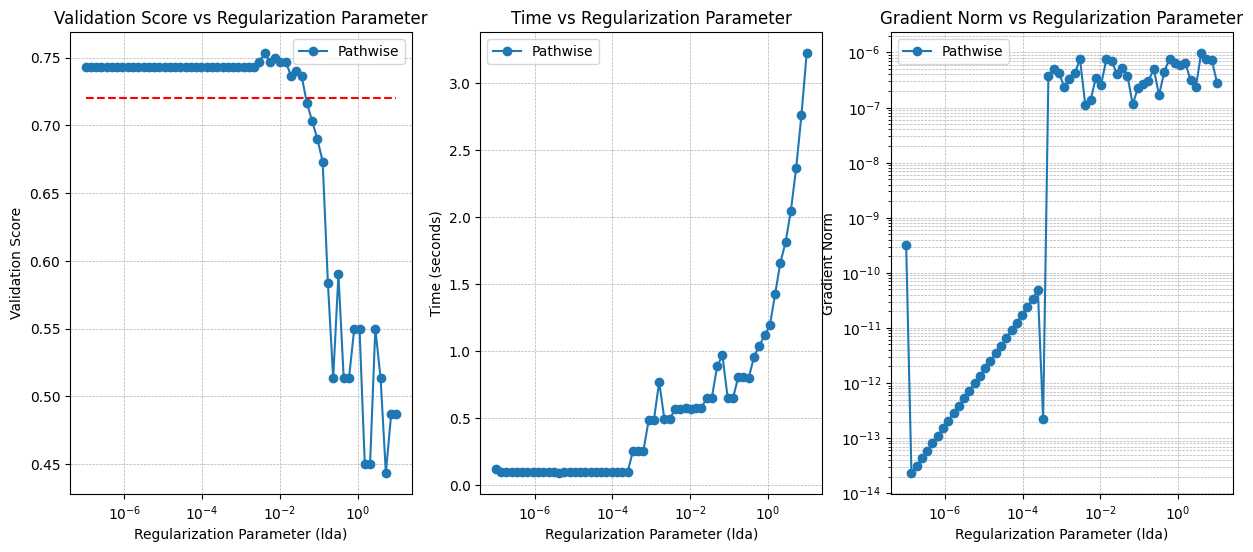

In [24]:
results['grad_norm'] = [float(x) for x in results['grad_norm']]
# results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['v_loss'] = [float(x) for x in results['v_loss']]
results['B_cos_sim'] = [float(x) for x in results['B_cos_sim']]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes = axes.flatten()
axes[0].plot(results['lda'], results['v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(results['baseline']['v_score'],
               xmin=results['lda'][0], xmax=results['lda'][-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(results['lda'], results['grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

In [ ]:
# ridge_model = deepcopy(best_model)
best_model = deepcopy(ridge_model)

sparsity_studies = []
for mode in [1,2,3]:
    rada_rgd_cfg = conf.rada_rgd_cfg.copy()
    rada_rgd_cfg.verbosity = 2
    rada_rgd_cfg.Tk= 100
    rada_rgd_cfg.max_it = 1000 #rada_rgd_cfg.max_it * 20
    rada_rgd_cfg.c1 = 0.01
    rada_rgd_cfg.rho = 1.5 # 2.5
    rada_rgd_cfg.eps = 1.0e-8
    rada_rgd_cfg.max_function_evals = rada_rgd_cfg.max_it * rada_rgd_cfg.Tk * 5
    # rada_rgd_cfg.max_line_search = 25
    rada_rgd_cfg.max_time = 30
    rada_rgd_cfg.beta1 = 30*3**0.5*0.1

    parameter: str = 'ldas'
    reg_path: list[float] = [float(i) for i in np.logspace(-4, 3, 40)]
    verbosity = 2
    print(f"Baseline val score: {best_val_score:.4f}")
    pstudy = TuckerBCDRegularizerPathStudy(
        parameter, reg_path, rada_rgd_cfg, mode=mode, verbosity=verbosity
        )
    # sparsity_logs.append(log)
    sparsity_studies.append(pstudy)
    best_model, best_hparams, log = pstudy(
        best_model,
        X=X_train,
        y=y_train,
        X_val=X_val,
        y_val=y_val
        )
    
    print(best_model._v_score)
    if log['improved']:
        print(f"Improved from {best_val_score:.4f} to {best_model._v_score:.4f}")
        best_val_score = best_model._v_score
    
    best_model._BCD_fit(use_dloader=False, X=X_train, y=y_train, X_val=X_val, y_val=y_val)

Baseline val score: 0.7033
Starting regularization path study for parameter: ldas mode: 1
Base model configuration:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.21826447283974873,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    ldas          Train Score    Val Score    Train Loss    Val Loss      Grad Norm     Time (s)    Num. Iter.    Termination Reason    
---------    ----------    -----------    ---------    ----------    ----------    ----------    --------    ----------    ------------------    
RADA RGD Optimizing...
k      t      f(x)                   <A(x), y>          Φ_k(x)                 ||grad Φ_k(x)||    ||y - prox_h(y + Ax)||    δ_k            β_k            ν_k            ζ_kt (Step Size)    ζ_kt (Armijo)    Step count    
---    ---    -------------------    ---------------

: 

# Sparse Tucker Regression Experiment Results:
- **Ground Truth Tucker Rank:** (3,3,3)
- Number of Training Samples: 900
- Validation set size: 300

|Sparsity|Tucker | Tucker Ridge |Sparse Tucker Ridge|
|---|---|---|---|
|12/90|0.67|0.74|0.78|
|24/90|0.66|0.70|0.71|
|   |   |   |   |   |

(<Figure size 700x600 with 1 Axes>,
 [<Axes: title={'center': 'Score vs Regularization Parameter'}, xlabel='Regularization Parameter (ldas)', ylabel='Score'>])

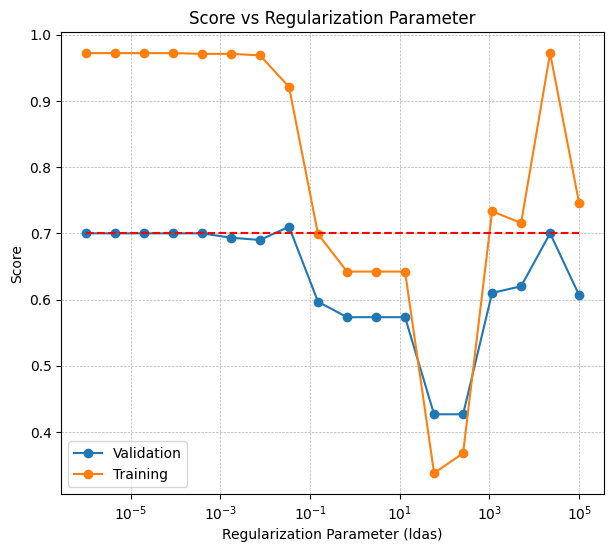

In [50]:
sparsity_studies[0].plot()

(<Figure size 700x600 with 1 Axes>,
 [<Axes: title={'center': 'Score vs Regularization Parameter'}, xlabel='Regularization Parameter (ldas)', ylabel='Score'>])

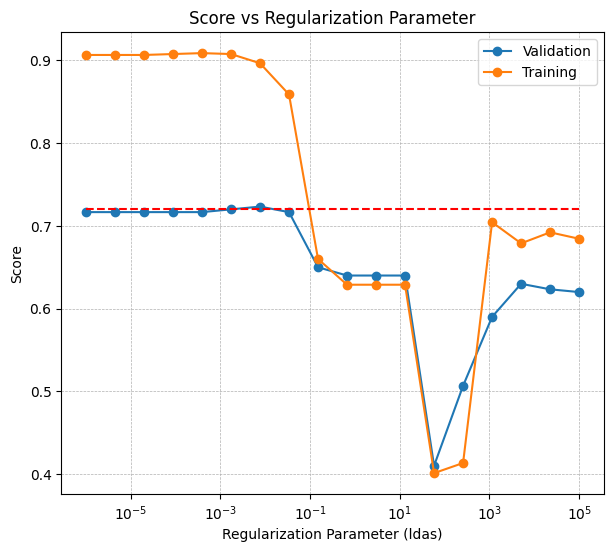

In [51]:
sparsity_studies[1].plot()

(<Figure size 700x600 with 1 Axes>,
 [<Axes: title={'center': 'Score vs Regularization Parameter'}, xlabel='Regularization Parameter (ldas)', ylabel='Score'>])

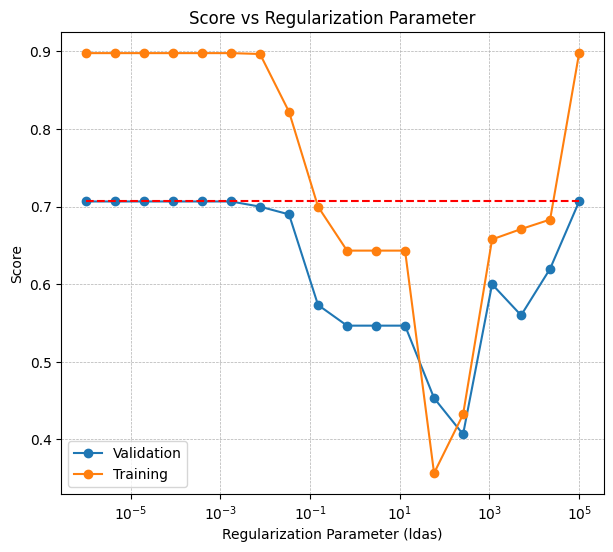

In [52]:
sparsity_studies[2].plot()